In [2]:
# import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.preprocessing import LabelEncoder
import joblib

# Set random seed for reproducibility
np.random.seed(42)

# Load dataset
print("Loading dataset...")
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')

# Display basic info
print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nClass distribution:\n{df['Recharge_Class'].value_counts()}")
print(f"\nMissing values:\n{df.isnull().sum()}")

# Define features and target
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
target_col = 'Recharge_Class'

X = df[feature_cols].values
y = df[target_col].values

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

Loading dataset...
Dataset shape: (51, 10)

Columns: ['Lineament_Density', 'Rainfall', 'TWI', 'Slope', 'DEM', 'Drainage_Density', 'LULC', 'Soil', 'Geology', 'Recharge_Class']

Class distribution:
Recharge_Class
1    37
0    14
Name: count, dtype: int64

Missing values:
Lineament_Density    0
Rainfall             0
TWI                  0
Slope                0
DEM                  0
Drainage_Density     0
LULC                 0
Soil                 0
Geology              0
Recharge_Class       0
dtype: int64

Feature matrix shape: (51, 9)
Target vector shape: (51,)


In [3]:
# Stratified split (maintains class proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

print(f"\nTrain class distribution:\n{pd.Series(y_train).value_counts()}")
print(f"\nTest class distribution:\n{pd.Series(y_test).value_counts()}")



Train set size: 40
Test set size: 11

Train class distribution:
1    29
0    11
Name: count, dtype: int64

Test class distribution:
1    8
0    3
Name: count, dtype: int64


In [3]:

# 4. Now 'X_test.index' WILL work because X_test is still a DataFrame
test_indices = X_test.index

# 5. Extract the 20% test wells from your original data
test_wells_df = df.loc[test_indices]

# Display the wells reserved for your WTF validation
print(f"Total Test Wells: {len(test_wells_df)}")
print(test_wells_df.head())

# # Save these for your thesis records
# test_wells_df.to_csv('wells_for_WTF_validation.csv')

AttributeError: 'numpy.ndarray' object has no attribute 'index'

In [4]:
rf_default = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train model
rf_default.fit(X_train, y_train)

print(f"\n✓ Training completed!")
print(f"OOB Score: {rf_default.oob_score_:.4f}")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s



✓ Training completed!
OOB Score: 0.9750


[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.3s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.3s finished


In [48]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import numpy as np
rf_default = RandomForestClassifier(
    n_estimators=90,
    max_depth=10,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train model
rf_default.fit(X_train, y_train)

print(f"\n✓ Training completed!")
print(f"OOB Score: {rf_default.oob_score_:.4f}")

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ------------------------------
# Classification Report (Binary)
# ------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],  # ✅ ONLY TWO
    zero_division=0
))

# ------------------------------
# Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ------------------------------
# ROC AUC (Binary)
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.1s finished



✓ Training completed!
OOB Score: 0.6250

Training Accuracy: 0.9750
Test Accuracy: 0.9091

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       1.00      0.67      0.80         3
        High       0.89      1.00      0.94         8

    accuracy                           0.91        11
   macro avg       0.94      0.83      0.87        11
weighted avg       0.92      0.91      0.90        11


Confusion Matrix:
[[2 1]
 [0 8]]

ROC AUC Score: 0.9583


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished


C:\Users\HP\AppData\Local\Temp\ipykernel_20728\3939437588.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


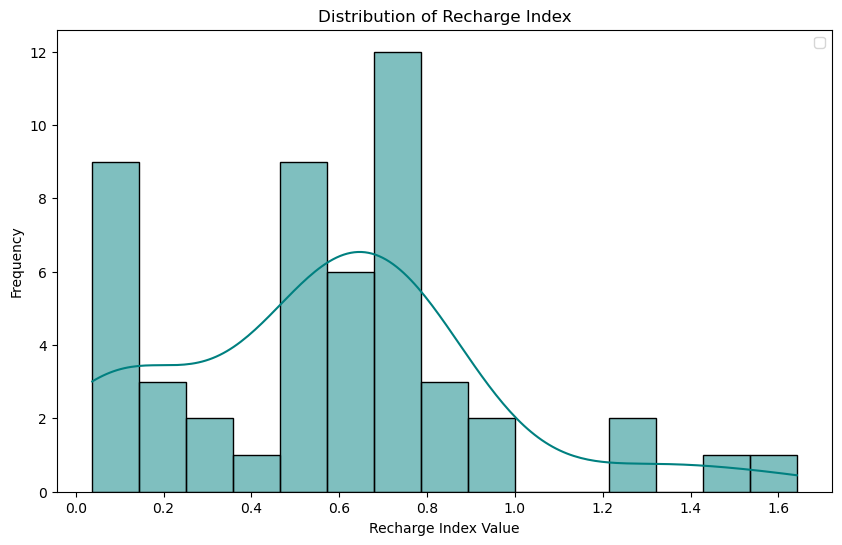

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
df1 = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Weekly_Groundwater_2023_Recharge binary1.xlsx')
# Plot the distribution of your Index
plt.figure(figsize=(10, 6))
sns.histplot(df1['Recharge_Index'], bins=15, kde=True, color='teal')
# plt.axvline(0.51, color='red', linestyle='--', label='Current Threshold (0.51)')
plt.title('Distribution of Recharge Index')
plt.xlabel('Recharge Index Value')
plt.ylabel('Frequency')
plt.legend()
plt.show()
# eta diye apatoto bujha jacche je kon threshold dhora jae, 0.4 suggest korlo gemini.

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

# --- ADDITION START: PRE-PROCESSING CATEGORICAL DATA ---
# Identify categorical columns to be encoded
categorical_cols = ['LULC', 'Soil', 'Geology']

# Apply One-Hot Encoding (keeps all other numerical columns as they are)
X_encoded = pd.get_dummies(df.drop(['Station', 'Recharge_Class'], axis=1), 
                           columns=categorical_cols)
y = df['Recharge_Class']

# Re-split the data with the newly encoded features
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)
# --- ADDITION END ---

# Your original model setup (unchanged)
rf_default = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=15,
    min_samples_split=5,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train model
rf_default.fit(X_train, y_train)

print(f"\n✓ Training completed!")
print(f"OOB Score: {rf_default.oob_score_:.4f}")

# Predictions
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# Accuracy
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Classification Report
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ROC AUC
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")

KeyError: "['Station'] not found in axis"

[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished



Training Accuracy: 1.0000
Test Accuracy: 0.9091

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       0.75      1.00      0.86         3
        High       1.00      0.88      0.93         8

    accuracy                           0.91        11
   macro avg       0.88      0.94      0.90        11
weighted avg       0.93      0.91      0.91        11


Confusion Matrix (Test Set):
[[3 0]
 [1 7]]


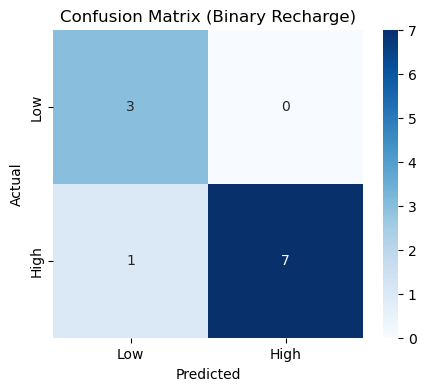


ROC AUC Score: 1.0000


In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ------------------------------
# Classification Report (Binary)
# ------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],  # Binary labels
    zero_division=0
))

# ------------------------------
# Confusion Matrix (Binary)
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
cm_labels = ['Low', 'High']

print("\nConfusion Matrix (Test Set):")
print(cm)

# Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=cm_labels,
    yticklabels=cm_labels,
    cmap='Blues'
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Binary Recharge)')
plt.show()

# ------------------------------
# ROC AUC Score (Binary)
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")


In [49]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 2️⃣ Setup Stratified K-Fold
# 5 folds is standard for small datasets
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3️⃣ Run Cross-Validation
scores = cross_val_score(
    rf_default,
    X,
    y,
    cv=skf,
    scoring='accuracy'
)

print(f"Accuracy per fold: {scores}")
print(f"Average Accuracy: {scores.mean():.4f}")
print(f"Standard Deviation: {scores.std():.4f}")


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0

Accuracy per fold: [1.  0.7 0.7 0.9 0.9]
Average Accuracy: 0.8400
Standard Deviation: 0.1200


[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.1s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished


In [50]:
from sklearn.metrics import accuracy_score, r2_score, mean_squared_error
import numpy as np

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# ------------------------------
# RMSE (classification)
# ------------------------------
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

# ------------------------------
# R² (optional, not standard for classification)
# ------------------------------
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Train RMSE: {rmse_train:.4f}")
print(f"Test RMSE: {rmse_test:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Test R²: {r2_test:.4f}")


Train Accuracy: 0.9750
Test Accuracy: 0.9091
Train RMSE: 0.1581
Test RMSE: 0.3015
Train R²: 0.8746
Test R²: 0.5417


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished


In [116]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, mean_squared_error, r2_score
import numpy as np

# ------------------------------
# 1. Custom Prediction Threshold
# ------------------------------
# Instead of default 0.5, we lower the bar for "Low" (Class 0)
# We predict "High" only if probability is > 0.6
y_probs_train = rf_default.predict_proba(X_train)[:, 1]
y_probs_test = rf_default.predict_proba(X_test)[:, 1]

threshold = 0.55 # 👈 ADJUST THIS: Higher value makes the model more likely to predict "Low"
y_pred_train = (y_probs_train > threshold).astype(int)
y_pred_test = (y_probs_test > threshold).astype(int)

# ------------------------------
# 2. Accuracy & Regression Metrics
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# RMSE and R2 (Treating classes as 0 and 1)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2 = r2_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

# ------------------------------
# 3. Classification Report
# ------------------------------
print("\n" + "="*80)
print(f"CLASSIFICATION REPORT (Test Set) - Threshold: {threshold}")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],
    zero_division=0
))

# ------------------------------
# 4. Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ------------------------------
# 5. ROC AUC
# ------------------------------
roc_auc = roc_auc_score(y_test, y_probs_test)
print(f"\nROC AUC Score: {roc_auc:.4f}")


Training Accuracy: 0.8000
Test Accuracy: 0.9091
RMSE: 0.3015
R2 Score: 0.5417

CLASSIFICATION REPORT (Test Set) - Threshold: 0.55
              precision    recall  f1-score   support

         Low       0.75      1.00      0.86         3
        High       1.00      0.88      0.93         8

    accuracy                           0.91        11
   macro avg       0.88      0.94      0.90        11
weighted avg       0.93      0.91      0.91        11


Confusion Matrix:
[[3 0]
 [1 7]]

ROC AUC Score: 0.9167


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished


In [51]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Use your NumPy arrays X, y
rf_default = RandomForestClassifier(random_state=42)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []

for train_index, test_index in skf.split(X, y):
    # Split data (NumPy indexing, no iloc)
    X_train_fold, X_test_fold = X[train_index], X[test_index]
    y_train_fold, y_test_fold = y[train_index], y[test_index]
    
    # Train model
    rf_default.fit(X_train_fold, y_train_fold)
    
    # Get probabilities for class 1
    y_probs_fold = rf_default.predict_proba(X_test_fold)[:, 1]
    
    # Apply threshold
    y_pred_fold = (y_probs_fold > 0.55).astype(int)
    
    # Accuracy
    acc = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(acc)

print(f"Accuracy per fold (0.55 threshold): {np.array(fold_accuracies)}")
print(f"Average Accuracy: {np.mean(fold_accuracies):.4f}")
print(f"Standard Deviation: {np.std(fold_accuracies):.4f}")


Accuracy per fold (0.55 threshold): [1. 1. 1. 1. 1.]
Average Accuracy: 1.0000
Standard Deviation: 0.0000


In [11]:
# Create DataFrame for CV results
cv_results = pd.DataFrame({
    'Fold': list(range(1, len(fold_accuracies)+1)),
    'Accuracy': fold_accuracies
})

# Add summary rows using pd.concat
summary = pd.DataFrame([
    {'Fold': 'Mean', 'Accuracy': np.mean(fold_accuracies)},
    {'Fold': 'Std', 'Accuracy': np.std(fold_accuracies)}
])

cv_results = pd.concat([cv_results, summary], ignore_index=True)

# Save to CSV
cv_results.to_csv(r'D:\Thesis\Main\Models\Random Forest\RF_CrossValidation_Results11.csv', index=False)
print("\n✓ CV results saved: RF_CrossValidation_Results11.csv")



✓ CV results saved: RF_CrossValidation_Results.csv


In [66]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# -----------------------------
# Load dataset
# -----------------------------
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']

X = df[feature_cols].values
y = df['Recharge_Class'].values

# -----------------------------
# K-Fold Cross-Validation
# -----------------------------
print("\n" + "="*80)
print("K-FOLD CROSS-VALIDATION (Random Forest, K=5)")
print("="*80)

rf_cv = RandomForestClassifier(
    n_estimators=90,
    max_depth=8,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

cv_results = cross_validate(
    rf_cv, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted'],
    return_train_score=True,
    n_jobs=-1
)

print("\nCross-Validation Results (5-Fold):")
print(f"  Mean Train Accuracy: {cv_results['train_accuracy'].mean():.4f} ± {cv_results['train_accuracy'].std():.4f}")
print(f"  Mean Test Accuracy:  {cv_results['test_accuracy'].mean():.4f} ± {cv_results['test_accuracy'].std():.4f}")
print(f"  Mean Precision:      {cv_results['test_precision_weighted'].mean():.4f} ± {cv_results['test_precision_weighted'].std():.4f}")
print(f"  Mean Recall:         {cv_results['test_recall_weighted'].mean():.4f} ± {cv_results['test_recall_weighted'].std():.4f}")
print(f"  Mean F1-Score:       {cv_results['test_f1_weighted'].mean():.4f} ± {cv_results['test_f1_weighted'].std():.4f}")

# # -----------------------------
# # Save CV results
# # -----------------------------
# cv_df = pd.DataFrame(cv_results)
# cv_df.to_csv(r'D:\Thesis\Main\Models\Random Forest\RF_CrossValidation_Results11.csv', index=False)
# print("\n✓ CV results saved: RF_CrossValidation_Results11.csv")

# # -----------------------------
# # Fit model on full dataset and save as .pkl
# # -----------------------------
# rf_cv.fit(X, y)
# joblib.dump(rf_cv, r'D:\Thesis\Main\Models\Random Forest\RF_KFold_Model11.pkl')
# print("✓ Random Forest K-Fold model saved: RF_KFold_Model11.pkl")



K-FOLD CROSS-VALIDATION (Random Forest, K=5)

Cross-Validation Results (5-Fold):
  Mean Train Accuracy: 0.8918 ± 0.0347
  Mean Test Accuracy:  0.8400 ± 0.1200
  Mean Precision:      0.8415 ± 0.1801
  Mean Recall:         0.8400 ± 0.1200
  Mean F1-Score:       0.8206 ± 0.1498


In [52]:
# Feature importance (Gini impurity-based)
feature_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': rf_default.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n" + "="*80)
print("FEATURE IMPORTANCE (Gini Impurity)")
print("="*80)
print(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='viridis')
plt.title('Random Forest Feature Importance (Gini Impurity)', fontsize=14, fontweight='bold')
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.savefig(r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Feature_Importance.png', dpi=600, bbox_inches='tight')
plt.close()
print("\n✓ Feature importance plot saved: RF_Feature_Importance.png")


FEATURE IMPORTANCE (Gini Impurity)
             Feature  Importance
2            Geology    0.445154
3                DEM    0.201565
0           Rainfall    0.125852
4   Drainage_Density    0.087451
8                TWI    0.073860
5              Slope    0.041653
6  Lineament_Density    0.011613
1               Soil    0.010747
7               LULC    0.002104


C:\Users\HP\AppData\Local\Temp\ipykernel_6900\4264922593.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance, x='Importance', y='Feature', palette='viridis')



✓ Feature importance plot saved: RF_Feature_Importance.png


In [53]:
# OOB error
oob_error = 1 - rf_default.oob_score_
print(f"\nOut-of-Bag (OOB) Error: {oob_error:.4f}")
print(f"Out-of-Bag (OOB) Accuracy: {rf_default.oob_score_:.4f}")

# OOB predictions
oob_decision = rf_default.oob_decision_function_
oob_pred = np.argmax(oob_decision, axis=1)
oob_accuracy = accuracy_score(y_train, oob_pred)
print(f"OOB Prediction Accuracy (manual): {oob_accuracy:.4f}")

AttributeError: 'RandomForestClassifier' object has no attribute 'oob_score_'

D:\Anaconda\Lib\site-packages\sklearn\ensemble\_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full dataset. In order to use "balanced" weights, use compute_class_weight ("balanced", classes, y). In place of y you can use a large enough sample of the full training set target to properly estimate the class frequency distributions. Pass the resulting weights as the class_weight parameter.
  warn(
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
D:\Anaconda\Lib\site-packages\sklearn\ensemble\_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
D:\Anaconda\Lib\site-packages\sklearn\ensemble\_forest.py:861: UserWarning: class_weight presets "balanced" or "balanced_subsample" are not recommended for warm_start if the fitted data differs from the full d

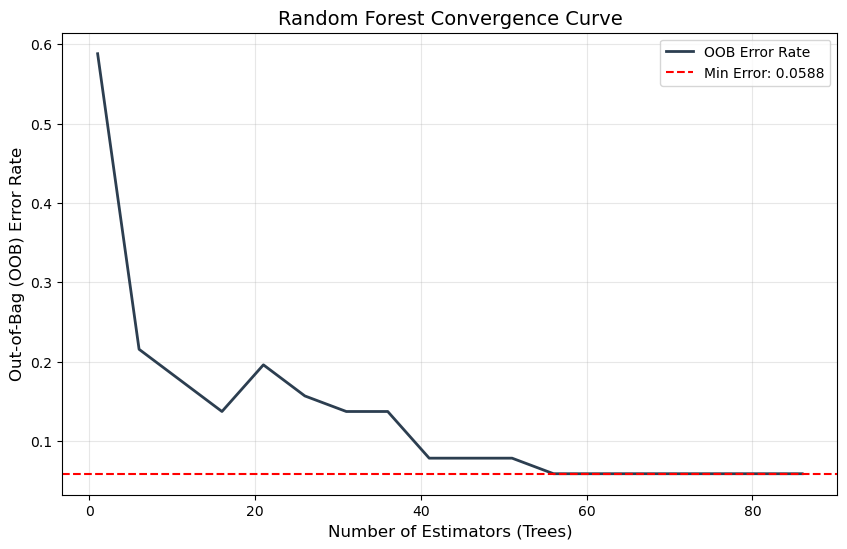

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

# Assuming X and y are your preprocessed features and labels
# We use warm_start=True to incrementally add trees and record the error
rf = RandomForestClassifier(n_estimators=90,
    max_depth=10,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1 ,
    warm_start=True)

n_estimators_range = range(1, 90, 5)  # From 1 to 250 trees
oob_errors = []

for i in n_estimators_range:
    rf.set_params(n_estimators=i)
    rf.fit(X, y)
    
    # Record the OOB error rate (1 - OOB Score)
    oob_error = 1 - rf.oob_score_
    oob_errors.append(oob_error)

# Plotting the RF Convergence Curve
plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, oob_errors, label="OOB Error Rate", color='#2c3e50', lw=2)
plt.axhline(y=min(oob_errors), color='r', linestyle='--', label=f'Min Error: {min(oob_errors):.4f}')
plt.xlabel("Number of Estimators (Trees)", fontsize=12)
plt.ylabel("Out-of-Bag (OOB) Error Rate", fontsize=12)
plt.title("Random Forest Convergence Curve", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# -------------------------------
# Separate Features and Target
# -------------------------------

X = df.drop(['Recharge_Class'], axis=1)
y = df['Recharge_Class']

categorical_cols = ['LULC', 'Soil', 'Geology']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

# -------------------------------
# Train-Test Split FIRST
# -------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# -------------------------------
# One-Hot Encoding (fit only on training data)
# -------------------------------

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', encoder, categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

# -------------------------------
# Random Forest Model
# -------------------------------

rf_default = RandomForestClassifier(
    n_estimators=150,           # slightly increased for stability
    max_depth=8,
    min_samples_leaf=5,
    min_samples_split=10,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=0
)

rf_default.fit(X_train_encoded, y_train)

print("\n✓ Training completed!")
print(f"OOB Score: {rf_default.oob_score_:.4f}")

# -------------------------------
# Predictions
# -------------------------------

y_pred_train = rf_default.predict(X_train_encoded)
y_pred_test = rf_default.predict(X_test_encoded)
y_pred_proba_test = rf_default.predict_proba(X_test_encoded)

# -------------------------------
# Evaluation
# -------------------------------

train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")


✓ Training completed!
OOB Score: 0.7250

Training Accuracy: 0.9000
Test Accuracy: 0.8182

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       0.67      0.67      0.67         3
        High       0.88      0.88      0.88         8

    accuracy                           0.82        11
   macro avg       0.77      0.77      0.77        11
weighted avg       0.82      0.82      0.82        11


Confusion Matrix:
[[2 1]
 [1 7]]

ROC AUC Score: 0.7083
